Analyst's prediction (written before results): 4 trend changes in German nights: the 2008 financial crisis, the January 2015 floor removal, covid in 2020, and a post-covid 'new normal' from 2022.

## Summary (Sprint 2, part A)

**German demand stepped down twice: in 2011-07 (franc surge) and in 2015-06 (after the floor removal). No break lines up with the 2008 crisis.**

- **Regimes.** Besides these two downward steps, PELT finds covid (2020-03) and a post-covid regime (2021-07). The breaks at 2006-01 and 2007-01 are **edge effects** near the start of the series and are not interpreted.
- **Post-covid (primary measure: level).** German nights are -2.5% vs their 2016-2019 level: the **level recovered, the growth path did not** (-15.4% vs the extrapolated 2016-2019 trend; secondary and fragile, because it extrapolates a 4-year trend over up to 7 years). The ±5% threshold for "level recovered" was set after seeing the results (at review).
- **The post-covid "new normal" is market-specific.** Swiss nights are +27.1% and US nights +77.9% above their 2016-2019 level, while German nights recovered their level (-2.5%).
- **Asymmetry.** German nights move with a stronger franc but not with a weaker one: with lags 0-12 the appreciation sum is 1.49 and the depreciation sum -0.34 (Wald p = 0.0015). This is consistent with **hysteresis** (once guests switch destination, they do not come back), a possible explanation that this notebook does not test.
- **Forecast features (direct strategy).** For horizon h, BIC keeps a single FX lag: lag h. The main model uses **one symmetric FX feature per horizon**. The appreciation/depreciation split is significant for h = 1-5 and not for h = 6 (p = 0.063); it is tested in Sprint 3 as a single experiment, judged by forecast error.

Every number in this summary is checked against the computed results by the last code cell ("Summary check").

# 02 — FX effect, part A: regimes, FX lags, symmetry

**Why this notebook exists.** The project's deliverable is a forecasting model of monthly hotel nights (canton x origin market, plus the 8 paired resorts), **1 to 6 months ahead**. This notebook designs its features by answering three questions:

1. **Regimes** — when did the trend of German, Swiss and US nights break? Is the post-covid period a new normal?
2. **FX lags** — which lags of EUR/CHF are linked to German nights? Forecasts use a **direct strategy**: the model for horizon h (1-6 months) may only use FX lags >= h, i.e. rates known at the forecast origin.
3. **Symmetry** — does a stronger franc move nights as much as a weaker one?

**Rules fixed before looking at results** (coded in `src/fx_effect.py`):
- Change points: PELT, piecewise-linear trend (each regime has its own level and slope), penalty = 3 x sigma^2 x ln(n) (BIC-style: level, slope, break date), sigma from the MAD of month-to-month changes, minimum regime 12 months. Main run on the full period; pre-covid run as a sensitivity check; Binseg forced to 1-5 breaks as a second sensitivity check.
- Seasonality removed first: log(nights) minus its month-of-year mean.
- Post-covid vs 2016-2019: the 2016-2019 trend is extrapolated over the post-covid regime; an average gap within +/-5% counts as "back to the pre-covid path".
- FX regressions: y = YoY log change of nights, x = YoY log change of CHF per EUR (x > 0 = weaker franc). Months whose YoY change touches covid (Mar 2020 - Dec 2021, in t or t-12) are excluded, i.e. through Dec 2022. Newey-West (HAC, 12 lags) standard errors, because YoY changes overlap. Only **sums** of lag coefficients are interpreted.
- Edge effects: breaks within 24 months (2 x minimum regime) of the start or end of a series are labelled "edge" and not interpreted.
- Feature decisions, per horizon h = 1..6: FX lag window chosen by BIC among lags h..L (L <= 12); main model: one symmetric FX feature per horizon; the Wald test on lags h-12 decides where the appreciation/depreciation split is worth testing as an experiment.
- Swiss nights are a placebo: same regressions, but a strong franc also makes holidays abroad cheaper for Swiss residents, so it is not a clean control.

Language is descriptive: "linked to", "moves with", never "causes".

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
from charts import (INK_SOFT, ORIGIN_COLORS, SOURCE_BFS, SOURCE_BFS_SNB, add_source, connect,
                    save, set_style, shade_covid, year_axis)
from features import deseasonalized_log, yoy_log_change
import fx_effect as fe

set_style()
pd.set_option("display.precision", 3)
con = connect()

nights = con.sql("""
    SELECT date, geo, origin, nights FROM monthly_nights WHERE level = 'canton'
""").df()
nights["date"] = pd.to_datetime(nights["date"])
assert (nights.groupby(["date", "origin"])["geo"].nunique() == 7).all(), "missing canton-month"
total = nights.groupby(["origin", "date"])["nights"].sum()     # sum of 7 cantons

eur = con.sql("SELECT date, chf_per_unit FROM fx WHERE currency = 'EUR' ORDER BY date").df()
eur = eur.assign(date=pd.to_datetime(eur["date"])).set_index("date")["chf_per_unit"].rename("EUR/CHF")

MARKETS = ["Germany", "Switzerland", "United States"]
series = {m: total[m].rename(m) for m in MARKETS}
print({m: f"{s.index.min():%Y-%m} -> {s.index.max():%Y-%m} ({len(s)} months)" for m, s in series.items()})
print(f"EUR/CHF: {eur.index.min():%Y-%m} -> {eur.index.max():%Y-%m} ({len(eur)} months)")

{'Germany': '2005-01 -> 2026-07 (259 months)', 'Switzerland': '2005-01 -> 2026-07 (259 months)', 'United States': '2005-01 -> 2026-07 (259 months)'}
EUR/CHF: 2005-08 -> 2026-08 (253 months)


## 1. Trend regimes (change points)

In [2]:
PRE_COVID_END = "2020-02-01"
des = {m: deseasonalized_log(s) for m, s in series.items()}

breaks, breaks_pre, segments, fits = {}, {}, {}, {}
for m, y in des.items():
    breaks[m] = fe.detect_breaks(y)
    breaks_pre[m] = fe.detect_breaks(y[:PRE_COVID_END])
    segments[m], fits[m] = fe.segment_table(y, breaks[m])

fx_log = np.log(eur).rename("EUR/CHF")
breaks["EUR/CHF"] = fe.detect_breaks(fx_log)
breaks_pre["EUR/CHF"] = fe.detect_breaks(fx_log[:PRE_COVID_END])

fmt = lambda bs: ", ".join(f"{b:%Y-%m}" for b in bs) or "none"
edges = {k: fe.edge_breaks(fx_log if k == "EUR/CHF" else des[k], v) for k, v in breaks.items()}
core = {k: [b for b in v if b not in edges[k]] for k, v in breaks.items()}
summary = pd.DataFrame({
    "breaks_full_period": {k: fmt(v) for k, v in core.items()},
    "edge_effects": {k: fmt(v) for k, v in edges.items()},
    "n_full": {k: len(v) for k, v in core.items()},
    "breaks_pre_covid": {k: fmt(v) for k, v in breaks_pre.items()},
    "n_pre": {k: len(v) for k, v in breaks_pre.items()},
})
summary

,breaks_full_period,edge_effects,n_full,breaks_pre_covid,n_pre
Germany,"2011-07, 2015-06, 2020-03, 2021-07","2006-01, 2007-01",4,"2006-01, 2007-01, 2011-07, 2015-06",4
Switzerland,"2016-06, 2019-06, 2020-06, 2021-07",2006-01,4,"2006-01, 2017-01",2
United States,"2008-06, 2017-04, 2018-04, 2019-04, 2020-04, 2...",none,8,"2006-02, 2007-02, 2008-06, 2011-07, 2017-04, 2...",6
EUR/CHF,"2008-10, 2009-10, 2010-10, 2011-10, 2013-01, 2...",2007-05,14,"2007-05, 2008-10, 2009-10, 2010-10, 2011-10, 2...",11


Regimes per market (full period): slope of the deseasonalized log series in each regime.

In [3]:
pd.concat({m: segments[m] for m in MARKETS}, names=["market", "regime"])

start      end  months  slope_pct_per_year
market        regime                                              
Germany       0       2005-01  2005-12      12             -26.498
              1       2006-01  2006-12      12             -19.208
              2       2007-01  2011-06      54              -2.776
              3       2011-07  2015-05      47              -3.259
              4       2015-06  2020-02      57               2.447
              5       2020-03  2021-06      16             115.441
              6       2021-07  2026-07      61               2.059
Switzerland   0       2005-01  2005-12      12             -11.267
              1       2006-01  2016-05     125               0.635
              2       2016-06  2019-05      36               5.729
              3       2019-06  2020-05      12             -72.271
              4       2020-06  2021-06      13              15.266
              5       2021-07  2026-07      61               0.543
United States 0       2005-01  2008-05      41               3.500
              1       2008-06  2017-03     106               3.659
              2       2017-04  2018-03      12             -16.809
              3       2018-04  2019-03      12             -12.850
              4       2019-04  2020-03      12             -52.018
              5       2020-04  2021-06      15             251.208
              6       2021-07  2022-06      12             312.027
              7       2022-07  2024-03      21              15.096
              8       2024-04  2026-07      28               2.125

**Sensitivity:** break dates when Binseg is forced to find exactly 1 to 5 breaks (full period).

In [4]:
forced = pd.concat([fe.forced_breaks(des[m]) for m in MARKETS] + [fe.forced_breaks(fx_log)], axis=1)
forced

,Germany,Switzerland,United States,EUR/CHF
n_breaks,,,,
1,2020-03,2021-04,2020-04,2010-06
2,"2020-03, 2021-07","2020-03, 2021-04","2020-04, 2022-06","2010-06, 2017-08"
3,"2011-07, 2020-03, 2021-07","2015-05, 2020-03, 2021-04","2008-06, 2020-04, 2022-06","2010-06, 2015-01, 2017-08"
4,"2011-07, 2015-06, 2020-03, 2021-07","2015-05, 2020-03, 2021-04, 2022-04","2008-06, 2020-04, 2021-06, 2022-06","2008-01, 2010-06, 2015-01, 2017-08"
5,"2006-01, 2011-07, 2015-06, 2020-03, 2021-07","2006-01, 2015-05, 2020-03, 2021-04, 2022-04","2008-06, 2019-04, 2020-04, 2021-06, 2022-06","2008-01, 2010-06, 2011-06, 2015-01, 2017-08"


**Analyst's prediction vs data** (German nights). The prediction in the first cell is not edited.

In [5]:
predicted = {"2008 financial crisis": "2008", "Jan 2015 floor removal": "2015-01",
             "covid 2020": "2020", "post-covid new normal": "2022"}
found = [f"{b:%Y-%m}" for b in breaks["Germany"]]
print(f"Predicted: 4 trend changes ({', '.join(predicted)}).")
print(f"Found by PELT (full period): {len(found)} breaks: {', '.join(found)} "
      f"(edge effects, not interpreted: {fmt(edges['Germany'])}).")
for event, key in predicted.items():
    hits = [f for f in found if f.startswith(key[:4])]
    print(f"  {event:<24} -> {'found: ' + ', '.join(hits) if hits else 'no break that year'}")

Predicted: 4 trend changes (2008 financial crisis, Jan 2015 floor removal, covid 2020, post-covid new normal).
Found by PELT (full period): 6 breaks: 2006-01, 2007-01, 2011-07, 2015-06, 2020-03, 2021-07 (edge effects, not interpreted: 2006-01, 2007-01).
  2008 financial crisis    -> no break that year
  Jan 2015 floor removal   -> found: 2015-06
  covid 2020               -> found: 2020-03
  post-covid new normal    -> no break that year


### Chart 7 — Trend regimes of German, Swiss and US nights

German pre-covid breaks, level step at the break (%): {'2011-07': -15.0, '2015-06': -15.3}


PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/07_change_points.png')

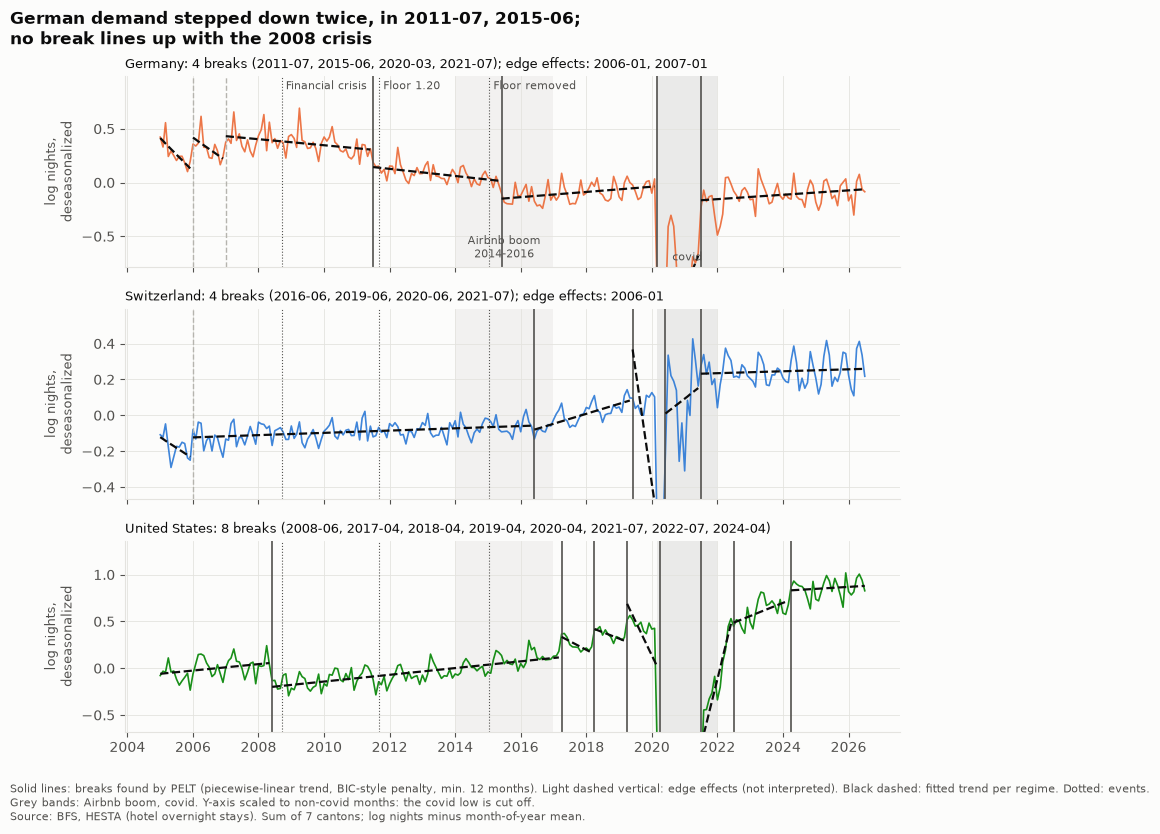

In [6]:
EVENTS = [("2008-09-15", "Financial crisis"), ("2011-09-06", "Floor 1.20"),
          ("2015-01-15", "Floor removed")]
fig, axes = plt.subplots(3, 1, figsize=(10, 8.4), sharex=True)
for ax, m in zip(axes, MARKETS):
    ax.axvspan(pd.Timestamp("2014-01-01"), pd.Timestamp("2016-12-31"), color=INK_SOFT,
               alpha=0.06, lw=0, zorder=0)
    shade_covid(ax, label=ax is axes[0])
    ax.plot(des[m].index, des[m], color=ORIGIN_COLORS[m], lw=1.2, alpha=0.9)
    for start in breaks[m]:                                 # one line per regime
        edge = start in edges[m]
        ax.axvline(start, color="#b5b4ae" if edge else INK_SOFT, lw=1.0 if edge else 1.2,
                   ls="--" if edge else "-")
    seg_id = np.searchsorted(np.array(breaks[m], dtype="datetime64[ns]"), fits[m].index.values, side="right")
    for k in np.unique(seg_id):
        part = fits[m][seg_id == k]
        ax.plot(part.index, part, color="#0b0b0b", lw=1.6, ls="--")
    for d, _ in EVENTS:
        ax.axvline(pd.Timestamp(d), color=INK_SOFT, lw=0.8, ls=":")
    ax.set_ylabel("log nights,\ndeseasonalized", fontsize=9)
    ax.set_title(f"{m}: {len(core[m])} breaks ({fmt(core[m])})"
                 + (f"; edge effects: {fmt(edges[m])}" if edges[m] else ""), loc="left", fontsize=9,
                 fontweight="normal")
    # Covid plunge would flatten every other regime: scale on non-covid months
    calm = des[m][(des[m].index < "2020-03-01") | (des[m].index > "2021-12-01")]
    pad = 0.25 * (calm.max() - calm.min())
    ax.set_ylim(calm.min() - pad, calm.max() + pad)
for d, text in EVENTS:
    axes[0].annotate(text, xy=(pd.Timestamp(d), 0.98), xycoords=("data", "axes fraction"),
                     xytext=(3, 0), textcoords="offset points", va="top", fontsize=8, color=INK_SOFT)
axes[0].annotate("Airbnb boom\n2014-2016", xy=(pd.Timestamp("2015-07-01"), 0.03),
                 xycoords=("data", "axes fraction"), ha="center", va="bottom", fontsize=8, color=INK_SOFT)
year_axis(axes[-1])
de_b = [b for b in core["Germany"] if b < pd.Timestamp("2020-01-01")]
jumps = {b: fe.level_jump(fits["Germany"], b) for b in de_b}
print("German pre-covid breaks, level step at the break (%):",
      {f"{b:%Y-%m}": round(j, 1) for b, j in jumps.items()})
assert len(de_b) == 2 and all(j < 0 for j in jumps.values()), "'stepped down twice' no longer holds"
assert not any(b.year in (2008, 2009) for b in core["Germany"]), "a break now lines up with 2008"
fig.suptitle(f"German demand stepped down twice, in {fmt(de_b)};\n"
             f"no break lines up with the 2008 crisis", x=0.01, ha="left", fontsize=12,
             fontweight="bold")
add_source(fig, SOURCE_BFS + ". Sum of 7 cantons; log nights minus month-of-year mean.",
           "Solid lines: breaks found by PELT (piecewise-linear trend, BIC-style penalty, min. 12 months). "
           "Light dashed vertical: edge effects (not interpreted). Black dashed: fitted trend per regime. "
           "Dotted: events.\nGrey bands: Airbnb boom, covid. "
           "Y-axis scaled to non-covid months: the covid low is cut off.")
fig.subplots_adjust(bottom=0.12, top=0.9, hspace=0.22)
save(fig, "07_change_points")

### Post-covid regime vs 2016-2019

Primary measure: the **level** of the post-covid regime against the 2016-2019 level. Secondary, fragile: the gap to the 2016-2019 trend extrapolated forward.

In [7]:
post = pd.DataFrame([fe.post_covid_vs_path(des[m], breaks[m]) for m in MARKETS]).set_index("market")
display(post)
for m, r in post.iterrows():
    print(f"{m} (post-covid regime from {r.post_covid_from}):\n"
          f"  PRIMARY   level {r.level_vs_2016_19_pct:+.1f}% vs 2016-2019 -> {r.level_verdict}\n"
          f"  SECONDARY growth {r.slope_post_covid_pct_yr:+.1f}%/yr vs {r.slope_2016_19_pct_yr:+.1f}%/yr before; "
          f"{r.gap_vs_2016_19_path_pct:+.1f}% vs the extrapolated 2016-2019 path -> {r.path_verdict} "
          f"(fragile: 4-year trend extrapolated over up to 7 years)")

,post_covid_from,level_vs_2016_19_pct,level_verdict,slope_2016_19_pct_yr,slope_post_covid_pct_yr,gap_vs_2016_19_path_pct,path_verdict
market,,,,,,,
Germany,2021-07,-2.456,level recovered,2.393,2.056,-15.445,below the 2016-2019 growth path
Switzerland,2021-07,27.074,level above 2016-2019,3.995,0.540,0.293,on the 2016-2019 growth path
United States,2024-04,77.931,level above 2016-2019,10.570,2.105,-15.553,below the 2016-2019 growth path


Germany (post-covid regime from 2021-07):
  PRIMARY   level -2.5% vs 2016-2019 -> level recovered
  SECONDARY growth +2.1%/yr vs +2.4%/yr before; -15.4% vs the extrapolated 2016-2019 path -> below the 2016-2019 growth path (fragile: 4-year trend extrapolated over up to 7 years)
Switzerland (post-covid regime from 2021-07):
  PRIMARY   level +27.1% vs 2016-2019 -> level above 2016-2019
  SECONDARY growth +0.5%/yr vs +4.0%/yr before; +0.3% vs the extrapolated 2016-2019 path -> on the 2016-2019 growth path (fragile: 4-year trend extrapolated over up to 7 years)
United States (post-covid regime from 2024-04):
  PRIMARY   level +77.9% vs 2016-2019 -> level above 2016-2019
  SECONDARY growth +2.1%/yr vs +10.6%/yr before; -15.6% vs the extrapolated 2016-2019 path -> below the 2016-2019 growth path (fragile: 4-year trend extrapolated over up to 7 years)


## 2. Which FX lags?

Symmetric model first. Individual lag coefficients are not identified (consecutive YoY changes share 11 of 12 months), so only sums are read.

In [8]:
x = yoy_log_change(eur)
yoy = {m: yoy_log_change(series[m]).rename(m) for m in ["Germany", "Switzerland"]}

# One common sample for every model: all lags 0-12 available, no covid in t or t-12
masks = {m: fe.sample_mask(y, fe.fx_lags(x.reindex(y.index), range(0, 13), split=True))
         for m, y in yoy.items()}
for m, mk in masks.items():
    idx = mk[mk].index
    print(f"{m}: N = {mk.sum()}, {idx.min():%Y-%m} -> {idx.max():%Y-%m}, "
          f"gap {idx[idx < '2021-01-01'].max():%Y-%m} -> {idx[idx > '2021-01-01'].min():%Y-%m}")
assert masks["Germany"].equals(masks["Switzerland"])

cum = pd.concat([fe.cumulative_effect(y, x.reindex(y.index), range(0, 13), masks[m])
                 for m, y in yoy.items()])
cum.pivot(index="lag", columns="market", values="cum_effect")

Germany: N = 194, 2007-08 -> 2026-07, gap 2020-02 -> 2023-01
Switzerland: N = 194, 2007-08 -> 2026-07, gap 2020-02 -> 2023-01


market,Germany,Switzerland
lag,,
0,-0.553,-0.085
1,0.325,0.036
2,0.409,0.365
3,0.445,-0.089
4,0.319,0.054
5,1.237,0.057
6,-0.046,0.041
7,1.216,0.071
8,0.828,0.469


The cumulative sum jumps from lag to lag, confirming that single lags cannot be read. Direct strategy: for horizon h the model may use lags h..12. For each h, BIC compares windows h..L on the same sample:

In [9]:
HORIZONS = range(1, 7)
win = pd.concat([fe.lag_window_bic(y, x.reindex(y.index), h, 12, masks[m]).assign(h=h)
                 for m, y in yoy.items() for h in HORIZONS], ignore_index=True)
best = win.loc[win.groupby(["market", "h"])["bic"].idxmin()].set_index(["market", "h"])
lag_text = lambda r, h: (f"lag {h} only" if r.last_lag == h else f"lags {h}-{r.last_lag}")
best["choice"] = [lag_text(r, h) for (m, h), r in best.iterrows()]
best["ci"] = [f"{r.sum_effect - 1.96 * r.se_sum:.2f} to {r.sum_effect + 1.96 * r.se_sum:.2f}"
              for _, r in best.iterrows()]
display(best[["choice", "sum_effect", "ci", "p_sum", "N"]])
for m in yoy:
    b = best.loc[m]
    print(f"{m}: BIC picks {', '.join(b['choice'])} for h = 1..6; coefficient "
          f"{b['sum_effect'].min():.2f} to {b['sum_effect'].max():.2f} (N = {b['N'].iloc[0]}).")

choice  sum_effect             ci      p_sum    N
market      h                                                       
Germany     1  lag 1 only       0.641   0.37 to 0.91  2.781e-06  194
            2  lag 2 only       0.677   0.37 to 0.98  1.547e-05  194
            3  lag 3 only       0.685   0.39 to 0.98  5.089e-06  194
            4  lag 4 only       0.735   0.39 to 1.08  2.631e-05  194
            5  lag 5 only       0.723   0.36 to 1.08  8.918e-05  194
            6  lag 6 only       0.631   0.28 to 0.98  4.437e-04  194
Switzerland 1  lag 1 only       0.133  -0.00 to 0.27  5.806e-02  194
            2  lag 2 only       0.146   0.02 to 0.27  2.452e-02  194
            3  lag 3 only       0.126  -0.01 to 0.26  7.719e-02  194
            4  lag 4 only       0.160   0.03 to 0.29  1.499e-02  194
            5  lag 5 only       0.186   0.08 to 0.30  9.770e-04  194
            6  lag 6 only       0.187   0.08 to 0.29  3.621e-04  194

Germany: BIC picks lag 1 only, lag 2 only, lag 3 only, lag 4 only, lag 5 only, lag 6 only for h = 1..6; coefficient 0.63 to 0.74 (N = 194).
Switzerland: BIC picks lag 1 only, lag 2 only, lag 3 only, lag 4 only, lag 5 only, lag 6 only for h = 1..6; coefficient 0.13 to 0.19 (N = 194).


### Chart 8 — FX effect at the lag chosen for each horizon

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/08_fx_lag_windows.png')

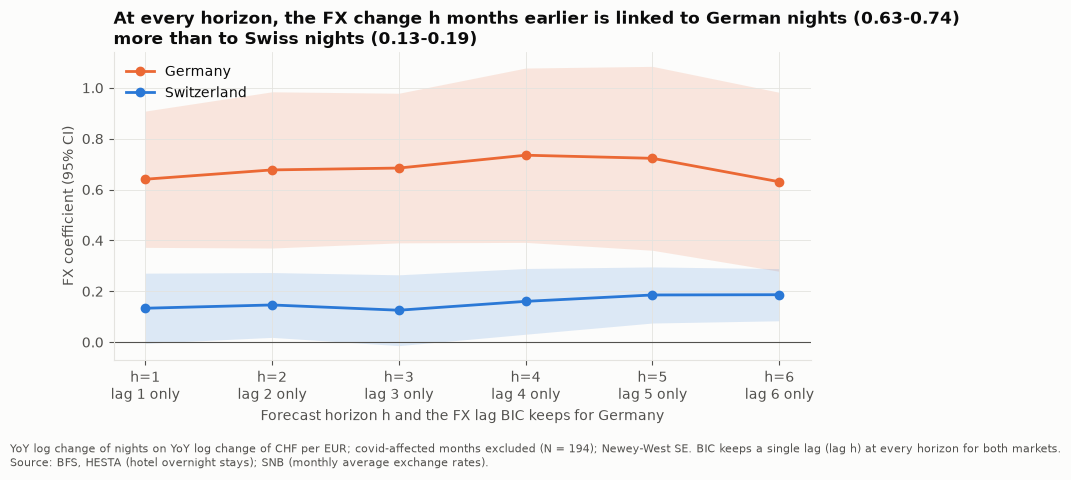

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for m in ["Germany", "Switzerland"]:
    b = best.loc[m]
    ax.plot(b.index, b["sum_effect"], marker="o", color=ORIGIN_COLORS[m], label=m)
    ax.fill_between(b.index, b["sum_effect"] - 1.96 * b["se_sum"],
                    b["sum_effect"] + 1.96 * b["se_sum"], color=ORIGIN_COLORS[m], alpha=0.15, lw=0)
ax.axhline(0, color=INK_SOFT, lw=0.8)
ax.set_xticks(list(HORIZONS), [f"h={h}\n{best.loc[('Germany', h), 'choice']}" for h in HORIZONS])
ax.set_xlabel("Forecast horizon h and the FX lag BIC keeps for Germany")
ax.set_ylabel("FX coefficient (95% CI)")
ax.legend(loc="upper left")
de, ch = best.loc["Germany"], best.loc["Switzerland"]
same = all(r.last_lag == h for (m, h), r in best.iterrows())
ax.set_title(f"At every horizon, the FX change h months earlier is linked to German nights "
             f"({de['sum_effect'].min():.2f}-{de['sum_effect'].max():.2f})\nmore than to Swiss nights "
             f"({ch['sum_effect'].min():.2f}-{ch['sum_effect'].max():.2f})", loc="left", fontsize=12)
add_source(fig, SOURCE_BFS_SNB + ".",
           f"YoY log change of nights on YoY log change of CHF per EUR; covid-affected months excluded "
           f"(N = {de['N'].iloc[0]}); Newey-West SE. "
           + ("BIC keeps a single lag (lag h) at every horizon for both markets." if same else ""))
fig.subplots_adjust(bottom=0.24)
save(fig, "08_fx_lag_windows")

## 3. Symmetric or asymmetric?

FX change split into depreciation (franc weakens, x > 0) and appreciation (franc strengthens, x < 0) parts. Positive sums mean nights move in the same direction as EUR/CHF (stronger franc, fewer nights). Wald H0: the two sums are equal. Lags 0-12 as designed; lags 6-12 is the set usable in a 6-month-ahead forecast. Swiss nights = placebo.

In [11]:
rows = []
for lags in [range(0, 13), range(6, 13)]:
    for m, y in yoy.items():
        rows.append(fe.asymmetry_test(y, x.reindex(y.index), lags, masks[m]))
asym = pd.DataFrame(rows).set_index(["lags", "market"])
display(asym)

for (lags, m), r in asym.iterrows():
    verdict = "asymmetry supported" if r.wald_p < fe.ALPHA else "asymmetry not supported"
    print(f"{m}, lags {lags}: appreciation sum {r.sum_appreciation:.2f} (p = {r.p_app:.4f}), "
          f"depreciation sum {r.sum_depreciation:.2f} (p = {r.p_dep:.4f}); "
          f"Wald p = {r.wald_p:.4f} -> {verdict} at 5% (N = {int(r.N)}).")

N  sum_appreciation  se_app      p_app  sum_depreciation  \
lags market                                                                    
0-12 Germany      194             1.492   0.228  5.826e-11            -0.338   
     Switzerland  194             0.149   0.106  1.575e-01             0.788   
6-12 Germany      194             1.009   0.210  1.498e-06             0.216   
     Switzerland  194             0.219   0.090  1.527e-02             0.428   

                  se_dep      p_dep  wald_stat  wald_p  
lags market                                             
0-12 Germany       0.427  4.292e-01     10.057   0.002  
     Switzerland   0.201  8.562e-05      5.530   0.019  
6-12 Germany       0.310  4.860e-01      3.454   0.063  
     Switzerland   0.146  3.293e-03      0.977   0.323

Germany, lags 0-12: appreciation sum 1.49 (p = 0.0000), depreciation sum -0.34 (p = 0.4292); Wald p = 0.0015 -> asymmetry supported at 5% (N = 194).
Switzerland, lags 0-12: appreciation sum 0.15 (p = 0.1575), depreciation sum 0.79 (p = 0.0001); Wald p = 0.0187 -> asymmetry supported at 5% (N = 194).
Germany, lags 6-12: appreciation sum 1.01 (p = 0.0000), depreciation sum 0.22 (p = 0.4860); Wald p = 0.0631 -> asymmetry not supported at 5% (N = 194).
Switzerland, lags 6-12: appreciation sum 0.22 (p = 0.0153), depreciation sum 0.43 (p = 0.0033); Wald p = 0.3229 -> asymmetry not supported at 5% (N = 194).


Per forecast horizon (direct strategy): asymmetry test on the usable lags h-12.

In [12]:
asym_h = pd.DataFrame([fe.asymmetry_test(y, x.reindex(y.index), range(h, 13), masks[m]) | {"h": h}
                       for m, y in yoy.items() for h in HORIZONS]).set_index(["market", "h"])
display(asym_h[["lags", "sum_appreciation", "sum_depreciation", "wald_p", "N"]])
split_h = {m: [h for h in HORIZONS if asym_h.loc[(m, h), "wald_p"] < fe.ALPHA] for m in yoy}
for m, hs in split_h.items():
    print(f"{m}: asymmetry significant at 5% for h = {hs or 'none'}; Wald p ranges "
          f"{asym_h.loc[m, 'wald_p'].min():.4f} to {asym_h.loc[m, 'wald_p'].max():.4f}.")

lags  sum_appreciation  sum_depreciation     wald_p    N
market      h                                                          
Germany     1  1-12             1.547            -0.195  1.849e-03  194
            2  2-12             1.469            -0.112  8.223e-04  194
            3  3-12             1.310             0.192  1.054e-02  194
            4  4-12             1.276             0.071  2.634e-03  194
            5  5-12             1.147             0.279  4.318e-02  194
            6  6-12             1.009             0.216  6.309e-02  194
Switzerland 1  1-12             0.187             0.726  4.285e-02  194
            2  2-12             0.210             0.640  8.182e-02  194
            3  3-12             0.149             0.665  1.984e-02  194
            4  4-12             0.184             0.604  3.791e-02  194
            5  5-12             0.195             0.559  8.611e-02  194
            6  6-12             0.219             0.428  3.229e-01  194

Germany: asymmetry significant at 5% for h = [1, 2, 3, 4, 5]; Wald p ranges 0.0008 to 0.0631.
Switzerland: asymmetry significant at 5% for h = [1, 3, 4]; Wald p ranges 0.0198 to 0.3229.


### Chart 9 — Appreciation vs depreciation effects

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/09_asymmetry.png')

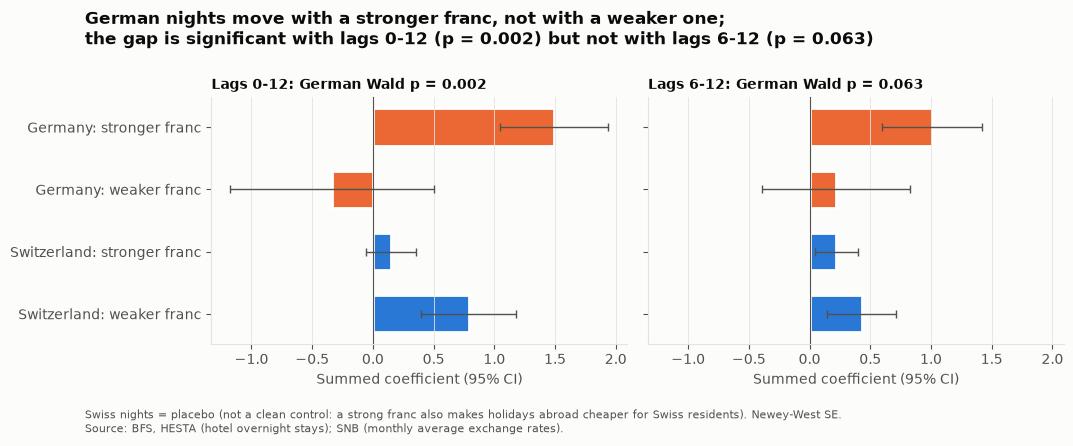

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True)
for ax, lags in zip(axes, ["0-12", "6-12"]):
    labels, est, se, col = [], [], [], []
    for m in ["Switzerland", "Germany"]:
        r = asym.loc[(lags, m)]
        for part, e, s in [("weaker franc", r.sum_depreciation, r.se_dep),
                           ("stronger franc", r.sum_appreciation, r.se_app)]:
            labels.append(f"{m}: {part}"); est.append(e); se.append(s); col.append(ORIGIN_COLORS[m])
    y = np.arange(len(labels))
    ax.barh(y, est, xerr=1.96 * np.array(se), color=col, height=0.6, edgecolor="white",
            linewidth=2, error_kw={"ecolor": INK_SOFT, "lw": 1, "capsize": 3})
    ax.set_yticks(y, labels if ax is axes[0] else [""] * len(labels))
    ax.axvline(0, color=INK_SOFT, lw=0.8)
    ax.grid(axis="y", visible=False)
    de_p = asym.loc[(lags, "Germany"), "wald_p"]
    ax.set_title(f"Lags {lags}: German Wald p = {de_p:.3f}", loc="left", fontsize=10)
    ax.set_xlabel("Summed coefficient (95% CI)")
p012, p612 = asym.loc[("0-12", "Germany"), "wald_p"], asym.loc[("6-12", "Germany"), "wald_p"]
fig.suptitle(f"German nights move with a stronger franc, not with a weaker one;\nthe gap is "
             f"significant with lags 0-12 (p = {p012:.3f}) but not with lags 6-12 (p = {p612:.3f})",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
add_source(fig, SOURCE_BFS_SNB + ".", "Swiss nights = placebo (not a clean control: a strong franc "
           "also makes holidays abroad cheaper for Swiss residents). Newey-West SE.")
fig.subplots_adjust(bottom=0.22, top=0.78, wspace=0.05)
save(fig, "09_asymmetry")

## Feature spec for Sprint 3

Target: monthly hotel nights for **49 series (7 cantons x 7 origin markets)** plus the **total of each of the 8 paired resorts** (luxury vs mid-range), forecast **1 to 6 months ahead** with a **direct strategy** (one model per horizon h), for seasonal pricing and seasonal staffing. Error is reported overall and for **peak-season months**: each series' **3 highest months by average share of annual nights, 2013-2019** (`seasonal_profile`), when seasonal staff is hired; always next to the seasonal-naive baseline. The decisions below are printed from this notebook's results:

In [14]:
de_post = post.loc["Germany"]
pre_breaks = [b for b in core["Germany"] if b < pd.Timestamp("2020-01-01")]

spec = [
    "REGIMES / COVID",
    f"  - Covid indicator Mar 2020 - Dec 2021 (PELT puts the German covid regime at "
    f"{fmt([b for b in breaks['Germany'] if b.year in (2020, 2021)])}).",
    f"  - Post-covid level indicator from {de_post.post_covid_from} for Germany ({de_post.level_verdict}, "
    f"{de_post.level_vs_2016_19_pct:+.1f}%; {de_post.path_verdict}); "
    f"Switzerland: {post.loc['Switzerland', 'level_verdict']}; "
    f"United States: {post.loc['United States', 'level_verdict']}.",
    f"  - German pre-covid level steps at {fmt(pre_breaks)}: let the model's level/trend change there "
    f"(piecewise trend or regime indicator), re-detected inside each training window to avoid look-ahead.",
    f"  - Edge breaks ({fmt(edges['Germany'])}) are not used.",
    "FX LAGS (direct strategy: horizon h uses lags >= h)",
    *[f"  - h={h}: YoY log change of the market's currency vs CHF, {best.loc[('Germany', h), 'choice']} "
      f"(Germany coef {best.loc[('Germany', h), 'sum_effect']:.2f}, p = {best.loc[('Germany', h), 'p_sum']:.4f})"
      for h in HORIZONS],
    "SYMMETRY",
    "  - Main model: ONE symmetric FX feature per horizon.",
    f"  - One experiment: split into appreciation/depreciation where the German Wald test on lags h-12 "
    f"has p < 0.05 (h = {split_h['Germany'] or 'none'}); kept only if it lowers forecast error.",
    "PEAK SEASON",
    "  - Each series' 3 highest months by average share of annual nights, 2013-2019 (seasonal_profile view).",
    "SCENARIOS",
    "  - FX after the forecast origin is never a model input; it enters only as scenarios (e.g. EUR/CHF at 0.90).",
]
print("\n".join(spec))

REGIMES / COVID
  - Covid indicator Mar 2020 - Dec 2021 (PELT puts the German covid regime at 2020-03, 2021-07).
  - Post-covid level indicator from 2021-07 for Germany (level recovered, -2.5%; below the 2016-2019 growth path); Switzerland: level above 2016-2019; United States: level above 2016-2019.
  - German pre-covid level steps at 2011-07, 2015-06: let the model's level/trend change there (piecewise trend or regime indicator), re-detected inside each training window to avoid look-ahead.
  - Edge breaks (2006-01, 2007-01) are not used.
FX LAGS (direct strategy: horizon h uses lags >= h)
  - h=1: YoY log change of the market's currency vs CHF, lag 1 only (Germany coef 0.64, p = 0.0000)
  - h=2: YoY log change of the market's currency vs CHF, lag 2 only (Germany coef 0.68, p = 0.0000)
  - h=3: YoY log change of the market's currency vs CHF, lag 3 only (Germany coef 0.68, p = 0.0000)
  - h=4: YoY log change of the market's currency vs CHF, lag 4 only (Germany coef 0.74, p = 0.0000)
  

## Limitations

- **Hotels only.** HESTA does not cover holiday flats or Airbnb: a shift of German guests to them would look like lost demand, and the 2014-2016 Airbnb boom overlaps the 2015 floor removal.
- **Overlapping events.** The 2008 crisis and the franc surge, and the 2015 floor removal and the Airbnb boom, happen at the same time; regimes cannot be attributed to one cause.
- **Short pre-covid windows.** 2016-2019 is four years; extrapolating its trend to 2026 (post-covid comparison) is a strong assumption. The ±5% "level recovered" threshold was set after seeing the results.
- **Feature choices selected on the full sample.** The FX lag choice (BIC) and the symmetry rule (Wald test) use all data up to 2026; Sprint 3 must validate them out of sample (rolling origin).
- **Break detection on the full sample** uses future data; it describes the past. Sprint 3 must re-detect breaks inside each training window.
- **YoY regressions:** overlapping changes, few independent FX episodes (2011, 2015, 2022), and a placebo that is not clean. Results are associations, not causal effects.
- **EUR/CHF is not trend-stationary**, so a piecewise-linear trend model splits it into many short regimes; its breaks are shown for comparison only.
- **Out of scope:** overbooking and nightly pricing need daily, hotel-level data (cancellations, no-shows, capacity), which this project does not have.

## Summary check

Every number in the summary at the top must match the results above.

In [15]:
de_post = post.loc["Germany"]
checks = {
    "steps at 2011-07 and 2015-06": [f"{b:%Y-%m}" for b in de_b] == ["2011-07", "2015-06"],
    "both steps are downward": all(j < 0 for j in jumps.values()),
    "no break in 2008-2009": not any(b.year in (2008, 2009) for b in core["Germany"]),
    "covid 2020-03, post-covid 2021-07":
        [f"{b:%Y-%m}" for b in core["Germany"] if b.year >= 2020] == ["2020-03", "2021-07"],
    "edge effects 2006-01, 2007-01": [f"{b:%Y-%m}" for b in edges["Germany"]] == ["2006-01", "2007-01"],
    "level -2.5%": round(de_post.level_vs_2016_19_pct, 1) == -2.5,
    "level recovered": de_post.level_verdict == "level recovered",
    "Swiss level +27.1%": round(post.loc["Switzerland", "level_vs_2016_19_pct"], 1) == 27.1,
    "US level +77.9%": round(post.loc["United States", "level_vs_2016_19_pct"], 1) == 77.9,
    "path -15.4%": round(de_post.gap_vs_2016_19_path_pct, 1) == -15.4,
    "appreciation 1.49": round(asym.loc[("0-12", "Germany"), "sum_appreciation"], 2) == 1.49,
    "depreciation -0.34": round(asym.loc[("0-12", "Germany"), "sum_depreciation"], 2) == -0.34,
    "Wald p 0.0015": round(asym.loc[("0-12", "Germany"), "wald_p"], 4) == 0.0015,
    "lag h at every h": all(best.loc[("Germany", h), "last_lag"] == h for h in HORIZONS),
    "split h = 1-5": split_h["Germany"] == [1, 2, 3, 4, 5],
    "h=6 p 0.063": round(asym_h.loc[("Germany", 6), "wald_p"], 3) == 0.063,
}
for name, ok in checks.items():
    print(f"{'OK  ' if ok else 'FAIL'} {name}")
assert all(checks.values()), "the summary at the top no longer matches the results"
con.close()
print(sorted(p.name for p in (Path.cwd().resolve().parent / "reports" / "figures").glob("0[7-9]_*.png")))

OK   steps at 2011-07 and 2015-06
OK   both steps are downward
OK   no break in 2008-2009
OK   covid 2020-03, post-covid 2021-07
OK   edge effects 2006-01, 2007-01
OK   level -2.5%
OK   level recovered
OK   Swiss level +27.1%
OK   US level +77.9%
OK   path -15.4%
OK   appreciation 1.49
OK   depreciation -0.34
OK   Wald p 0.0015
OK   lag h at every h
OK   split h = 1-5
OK   h=6 p 0.063
['07_change_points.png', '08_fx_lag_windows.png', '09_asymmetry.png']
